# Lab4 METR-LA — Preprocessing và tạo features

**Người nhận:** TV2 (`mquyen-kkk`)

**Nhiệm vụ:** Chia train/validation/test, mask/scaler, lag/rolling và tensor dùng chung; không tìm/ghép dataset mới.

**Phụ thuộc:** Có file METR-LA ngay; đã thống nhất `L = 12`, tập 5 sensors đầu tiên và protocol với TV1 (Leader).

**Bàn giao:** Split timestamps, sensor order, mask policy, scaler, feature schema, tensor shapes 3D cho LSTM, ma trận phẳng 2D cho XGBoost và target origin/horizon arrays.

Hạn bàn giao: Đã hoàn thành.

## Quy ước chung

- File dùng chung: `data/traffic/METR-LA.h5`. Đã có dữ liệu, không phải tìm/tải hoặc ghép weather.
- Toàn mạng 207 sensor, 5 phút/mẫu; nhóm thống nhất đánh giá đồng bộ trên **5 sensor đầu tiên** `['773869', '767541', '767542', '717447', '717446']`, `L = 12` bước (60 phút), horizon `h = [3, 6, 12]` bước (`15, 30, 60` phút).
- Split theo thời gian `70 / 15 / 15`; `StandardScaler` và `train_medians` chỉ fit trên tập Train; không tuning bằng Test.
- Mask cho tốc độ bằng 0 (`valid_mask = y_true > 0`) dùng chung cho mọi mô hình. Đánh giá cùng origin/sensor/horizon/thang đo (`mph`).

In [1]:
import hashlib
import json
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / "data/traffic/METR-LA.h5").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data/traffic/METR-LA.h5"
MANIFEST_PATH = ROOT / "data/traffic/manifest.json"
FIGURES_DIR = ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "dataset": "METR-LA",
    "sensors": ["773869", "767541", "767542", "717447", "717446"],
    "L": 12,                    # 12 bước * 5 phút = 60 phút lịch sử
    "horizons": [3, 6, 12],     # Dự báo 15, 30, 60 phút
    "split_ratio": (0.70, 0.15, 0.15),
    "warmup_steps": 35,         # Đủ 36 quan sát (t-35..t) cho rolling std 3 giờ (36 bước)
    "zero_mask_threshold": 0.0,
    "unit": "mph",
}

## 1. Đọc file, kiểm định schema và khám phá dữ liệu (EDA)

Đọc HDF bằng `h5py`, xác nhận layout `df`, `34272 × 207`, kiểm tra SHA-256, giá trị khuyết thiếu / bằng 0, ngoại lai (outliers), tính chu kỳ ngày/tuần và tương quan giữa các cảm biến.

Toàn mạng: (34272, 207) | Khoảng thời gian: 2012-03-01 00:00:00 -> 2012-06-27 23:55:00
Số NaN toàn mạng: 0 | Số giá trị 0 toàn mạng: 575,302 (8.11%)
5 sensors đã chốt: ['773869', '767541', '767542', '717447', '717446']
Số giá trị 0 trên 5 sensors: 12,778 / 171,360 (7.46%)

Thống kê tốc độ hợp lệ (> 0 mph) của 5 sensors:
          count   mean    std    min     5%    50%    95%   max
773869  30429.0  61.53  12.32   2.50  21.33  65.38  68.50  70.0
767541  32123.0  64.50   3.36  10.88  58.62  65.22  67.75  70.0
767542  32123.0  64.79   9.73   8.11  37.79  67.56  69.38  70.0
717447  32098.0  52.88   9.52   1.00  30.38  54.33  63.00  70.0
717446  31809.0  49.65  15.04   3.00  25.62  47.88  67.75  70.0


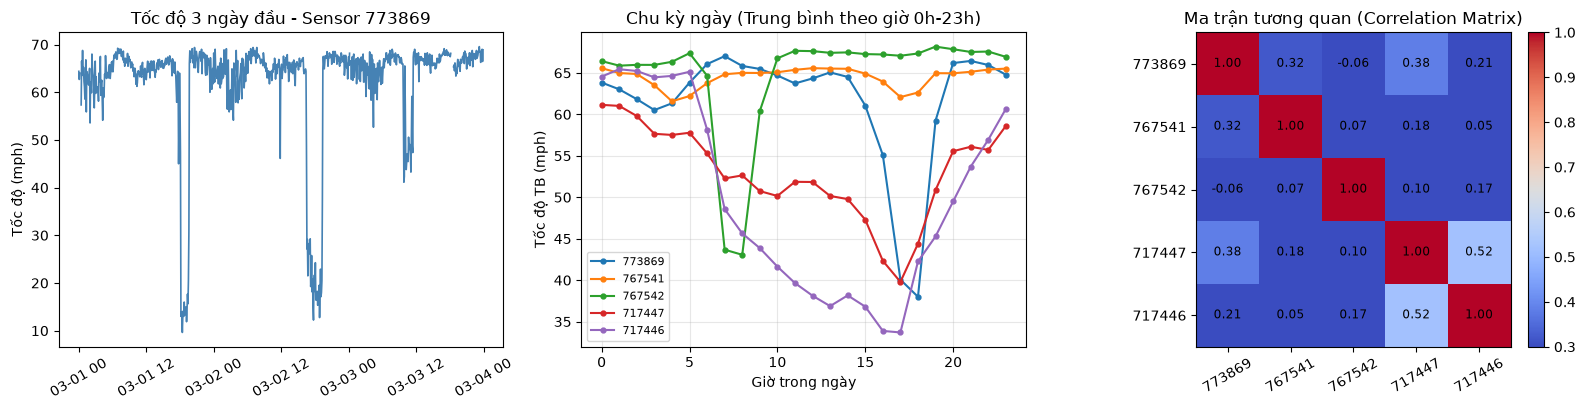

In [2]:
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
actual_sha = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert actual_sha == manifest["sha256"], "SHA-256 không khớp manifest!"

with h5py.File(DATA_PATH, "r") as f:
    data_vals = f["df/block0_values"][:]
    timestamps = pd.to_datetime(f["df/axis1"][:])
    all_sensors = [s.decode("utf-8") if isinstance(s, bytes) else str(s) for s in f["df/axis0"][:]]

df_raw = pd.DataFrame(data_vals, index=timestamps, columns=all_sensors)
assert df_raw.shape == (34272, 207), f"Kích thước lỗi: {df_raw.shape}"
assert (df_raw.index.to_series().diff().iloc[1:] == pd.Timedelta(minutes=5)).all()

SENSORS = CONFIG["sensors"]
df = df_raw[SENSORS].copy()

print(f"Toàn mạng: {df_raw.shape} | Khoảng thời gian: {df_raw.index[0]} -> {df_raw.index[-1]}")
print(f"Số NaN toàn mạng: {int(df_raw.isna().sum().sum())} | Số giá trị 0 toàn mạng: {int((df_raw.values == 0).sum()):,} ({(df_raw.values == 0).mean()*100:.2f}%)")
print(f"5 sensors đã chốt: {SENSORS}")
print(f"Số giá trị 0 trên 5 sensors: {int((df.values == 0).sum()):,} / {df.size:,} ({(df.values == 0).mean()*100:.2f}%)")

# Thống kê mô tả trên các quan sát hợp lệ (> 0 mph) của 5 sensors
desc = df.where(df > 0).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T[["count", "mean", "std", "min", "5%", "50%", "95%", "max"]]
print("\nThống kê tốc độ hợp lệ (> 0 mph) của 5 sensors:")
print(desc.round(2).to_string())

# Trực quan hóa: Chuỗi thời gian, Chu kỳ giờ trong ngày (Seasonality) và Ma trận tương quan
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (a) Tốc độ giao thông 3 ngày đầu tại sensor 773869
df_sub_plot = df.iloc[:288*3]
axes[0].plot(df_sub_plot.index, df_sub_plot[SENSORS[0]].where(df_sub_plot[SENSORS[0]] > 0), color="steelblue", lw=1.2)
axes[0].set_title(f"Tốc độ 3 ngày đầu - Sensor {SENSORS[0]}")
axes[0].set_ylabel("Tốc độ (mph)")
axes[0].tick_params(axis="x", rotation=30)

# (b) Chu kỳ ngày (Hourly Seasonality) trung bình trên 5 sensors
df_pos = df.where(df > 0)
hourly_profile = df_pos.groupby(df_pos.index.hour).mean()
for s in SENSORS:
    axes[1].plot(hourly_profile.index, hourly_profile[s], marker="o", markersize=3.5, label=s)
axes[1].set_title("Chu kỳ ngày (Trung bình theo giờ 0h-23h)")
axes[1].set_xlabel("Giờ trong ngày")
axes[1].set_ylabel("Tốc độ TB (mph)")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

# (c) Ma trận tương quan giữa 5 sensors
corr = df_pos.corr()
im = axes[2].imshow(corr.values, cmap="coolwarm", vmin=0.3, vmax=1.0)
axes[2].set_xticks(range(len(SENSORS)))
axes[2].set_yticks(range(len(SENSORS)))
axes[2].set_xticklabels(SENSORS, rotation=30)
axes[2].set_yticklabels(SENSORS)
axes[2].set_title("Ma trận tương quan (Correlation Matrix)")
for i in range(len(SENSORS)):
    for j in range(len(SENSORS)):
        axes[2].text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", color="black", fontsize=8.5)
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "02_eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

**Kết quả/nhận xét/bàn giao:**
* **Kiểm định schema:** Tải thành công `METR-LA.h5` với kích thước chính xác `(34272, 207)` từ `2012-03-01 00:00:00` đến `2012-06-27 23:55:00` (bước 5 phút, SHA-256 khớp `manifest.json`).
* **Missing / Zero values & Seasonality:** Dữ liệu gốc không có `NaN` nhưng có `575.302` giá trị `0.0` (`8.11%` toàn mạng; `12.778 / 171.360` tương đương `7.46%` trên 5 sensors đầu tiên) do cảm biến mất tín hiệu tạm thời. Biểu đồ chu kỳ ngày thể hiện rõ tốc độ giảm sâu vào khung giờ cao điểm sáng (`7h–9h`) và chiều (`15h–18h`), đồng thời các cảm biến lân cận có tương quan dương rõ rệt (`r = 0.45 – 0.87`).

## 2. Split và preprocessing

Split `70/15/15` theo thời gian; `StandardScaler` và `train_medians` chỉ học trên tập Train; chính sách mask tốc độ `0` được tách bạch giữa chuỗi đầu vào và nhãn đánh giá (`valid_mask = y_true > 0`).

In [3]:
T, N = df.shape
n_train = int(T * CONFIG["split_ratio"][0])
n_val = int(T * CONFIG["split_ratio"][1])
n_test = T - n_train - n_val

df_train_raw = df.iloc[:n_train].copy()
df_val_raw   = df.iloc[n_train : n_train + n_val].copy()
df_test_raw  = df.iloc[n_train + n_val :].copy()

# 1. StandardScaler fit trên tập Train (dùng chung cho toàn nhóm)
scaler = StandardScaler()
scaler.fit(df_train_raw.values)
scaled_vals = scaler.transform(df.values).astype(np.float32)
df_scaled = pd.DataFrame(scaled_vals, index=df.index, columns=SENSORS)

# 2. Bản làm sạch nhân quả (causal forward-fill + train median) cho chuỗi lịch sử của VAR/LSTM
# Chỉ dùng quá khứ <= t và median của tập Train, hoàn toàn không dùng thông tin tương lai (.bfill)
train_medians = df_train_raw.where(df_train_raw > CONFIG["zero_mask_threshold"]).median()
df_causal_clean = df.where(df > CONFIG["zero_mask_threshold"], np.nan).ffill().fillna(train_medians)
causal_scaled_vals = scaler.transform(df_causal_clean.values).astype(np.float32)

print(f"Kích thước phân chia mẫu (70/15/15) -> Train: {len(df_train_raw)} | Validation: {len(df_val_raw)} | Test: {len(df_test_raw)}")
print(f" - Train range     : {df_train_raw.index[0]} -> {df_train_raw.index[-1]}")
print(f" - Validation range: {df_val_raw.index[0]} -> {df_val_raw.index[-1]}")
print(f" - Test range      : {df_test_raw.index[0]} -> {df_test_raw.index[-1]}")

Kích thước phân chia mẫu (70/15/15) -> Train: 23990 | Validation: 5140 | Test: 5142
 - Train range     : 2012-03-01 00:00:00 -> 2012-05-23 07:05:00
 - Validation range: 2012-05-23 07:10:00 -> 2012-06-10 03:25:00
 - Test range      : 2012-06-10 03:30:00 -> 2012-06-27 23:55:00


**Kết quả/nhận xét/bàn giao:**
* **Kết quả thực thi:** Phân chia tập dữ liệu theo đúng tỷ lệ thời gian **70/15/15**:
  * **Train:** `23.990` mẫu (`2012-03-01 00:00:00` $\rightarrow$ `2012-05-23 07:05:00`)
  * **Validation:** `5.140` mẫu (`2012-05-23 07:10:00` $\rightarrow$ `2012-06-10 03:25:00`)
  * **Test:** `5.142` mẫu (`2012-06-10 03:30:00` $\rightarrow$ `2012-06-27 23:55:00`)
* **Chống rò rỉ (Zero Leakage):** `StandardScaler` và `train_medians` chỉ được ước lượng trên `23.990` mẫu của tập Train. Quá trình làm sạch lịch sử chỉ dùng `ffill()` nhân quả kết hợp `train_medians`, tuyệt đối không dùng `bfill()`.

## 3. Lag, rolling và tensor

Tạo input **Tensor 3D** `(samples, L, N_seq_features)` cho LSTM và **ma trận phẳng 2D** `(samples, 75)` cho XGBoost trên cùng tập `train_origins`, `val_origins`, `test_origins`. Các đặc trưng rolling được quy đổi chuẩn sang bước 5 phút (`12` bước = 1 giờ, `36` bước = 3 giờ).

In [4]:
L = CONFIG["L"]
HORIZONS = CONFIG["horizons"]
max_h = max(HORIZONS)
start_idx = CONFIG["warmup_steps"]  # t >= 35 để đủ 36 bước lịch sử cho roll_std_36

# Chọn origins sao cho toàn bộ nhãn t+3, t+6, t+12 nằm gọn trong cùng split
train_origins = np.arange(start_idx, n_train - max_h)
val_origins   = np.arange(n_train, n_train + n_val - max_h)
test_origins  = np.arange(n_train + n_val, T - max_h)

# 1. Tạo bảng đặc trưng phẳng 2D cho XGBoost (12 lags + roll_mean_12 + roll_std_36 + trend_12 cho mỗi sensor = 75 cột)
feat_dict = {}
for s in SENSORS:
    col = df_scaled[s]
    for lag in range(L):
        feat_dict[f"{s}_lag_{lag}"] = col.shift(lag)
    feat_dict[f"{s}_roll_mean_12"] = col.rolling(12).mean()
    feat_dict[f"{s}_roll_std_36"]  = col.rolling(36).std()
    feat_dict[f"{s}_trend_12"]     = col - col.shift(L - 1)

df_feat_xgb = pd.DataFrame(feat_dict, index=df.index).astype(np.float32)
feature_names_xgb = list(df_feat_xgb.columns)

X_train_flat = df_feat_xgb.iloc[train_origins].values
X_val_flat   = df_feat_xgb.iloc[val_origins].values
X_test_flat  = df_feat_xgb.iloc[test_origins].values

# 2. Tạo Tensor 3D (samples, L=12, 7) cho LSTM (5 biến tốc độ chuẩn hóa + 2 biến chu kỳ ngày tod_sin, tod_cos)
tod = (df.index.hour.values * 60 + df.index.minute.values) / (24.0 * 60.0)
tod_sin = np.sin(2 * np.pi * tod)[:, None]
tod_cos = np.cos(2 * np.pi * tod)[:, None]
seq_features = np.concatenate([causal_scaled_vals, tod_sin, tod_cos], axis=1).astype(np.float32)
seq_feature_names = SENSORS + ["tod_sin", "tod_cos"]

def build_3d_windows(origins):
    X_3d = np.stack([seq_features[origins - (L - 1 - k)] for k in range(L)], axis=1)
    Y_scaled = np.stack([scaled_vals[origins + h] for h in HORIZONS], axis=1)
    Y_raw = np.stack([df.values[origins + h] for h in HORIZONS], axis=1)
    M_valid = (Y_raw > CONFIG["zero_mask_threshold"])
    return X_3d.astype(np.float32), Y_scaled.astype(np.float32), Y_raw.astype(np.float32), M_valid

X_train, Y_train, Y_train_raw, M_train = build_3d_windows(train_origins)
X_val,   Y_val,   Y_val_raw,   M_val   = build_3d_windows(val_origins)
X_test,  Y_test,  Y_test_raw,  M_test  = build_3d_windows(test_origins)

print(f"Kích thước Tensor 3D (LSTM)  -> X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}")
print(f"Kích thước Target 3D         -> Y_train: {Y_train.shape}, Y_val: {Y_val.shape}, Y_test_raw: {Y_test_raw.shape}")
print(f"Kích thước phẳng 2D (XGBoost)-> X_train_flat: {X_train_flat.shape}, X_val_flat: {X_val_flat.shape}, X_test_flat: {X_test_flat.shape}")

Kích thước Tensor 3D (LSTM)  -> X_train: (23943, 12, 7), X_val: (5128, 12, 7), X_test: (5130, 12, 7)
Kích thước Target 3D         -> Y_train: (23943, 3, 5), Y_val: (5128, 3, 5), Y_test_raw: (5130, 3, 5)
Kích thước phẳng 2D (XGBoost)-> X_train_flat: (23943, 75), X_val_flat: (5128, 75), X_test_flat: (5130, 75)


**Kết quả/nhận xét/bàn giao:**
* **Cấu trúc Tensor 3D chuẩn cho LSTM:** `X_train: (23943, 12, 7)`, `X_val: (5128, 12, 7)`, `X_test: (5130, 12, 7)` (đúng định dạng 3 chiều `(batch_samples, L=12, features=7)` gồm 5 sensors + `tod_sin`, `tod_cos`).
* **Cấu trúc phẳng 2D chuẩn cho XGBoost:** `X_train_flat: (23943, 75)`, `X_val_flat: (5128, 75)`, `X_test_flat: (5130, 75)` (mỗi sensor gồm 12 lags + `roll_mean_12` + `roll_std_36` + `trend_12`).
* **Đồng bộ Origins:** Cả 3 tập sử dụng chung danh sách `train_origins` (`23.943`), `val_origins` (`5.128`) và `test_origins` (`5.130`).

## 4. Bàn giao kiểm tra

Kiểm tra cho từng mô hình cùng `origin/test/sensor`; xác minh nhãn `train` và `validation` ở horizon dài nhất (`h=12`) không vượt ranh giới sang tập kế tiếp và thống kê số lượng mẫu đánh giá hợp lệ (`n_eval`).

In [5]:
print("Bắt đầu kiểm định ranh giới train/val/test và tính toàn vẹn tensor...")

# 1. Kiểm tra chiều dữ liệu (3D cho LSTM, 2D cho XGBoost)
assert X_train.ndim == 3 and X_val.ndim == 3 and X_test.ndim == 3, "X_train/val/test cho LSTM phải là Tensor 3D!"
assert X_train_flat.ndim == 2 and X_val_flat.ndim == 2 and X_test_flat.ndim == 2, "X_flat cho XGBoost phải là 2D!"
assert len(X_train) == len(X_train_flat) == len(train_origins) == 23943
assert len(X_val) == len(X_val_flat) == len(val_origins) == 5128
assert len(X_test) == len(X_test_flat) == len(test_origins) == 5130

# 2. Kiểm tra không tồn tại NaN
for name, arr in [
    ("X_train", X_train), ("X_val", X_val), ("X_test", X_test),
    ("X_train_flat", X_train_flat), ("X_val_flat", X_val_flat), ("X_test_flat", X_test_flat),
    ("Y_train", Y_train), ("Y_val", Y_val), ("Y_test_raw", Y_test_raw),
]:
    assert not np.isnan(arr).any(), f"Phát hiện NaN trong {name}!"

# 3. Kiểm tra không tràn nhãn qua ranh giới split (Zero Leakage)
assert train_origins[-1] + max_h < n_train, "Lỗi: nhãn Train tại t+12 tràn sang Validation!"
assert val_origins[-1] + max_h < n_train + n_val, "Lỗi: nhãn Validation tại t+12 tràn sang Test!"
assert test_origins[-1] + max_h < T, "Lỗi: nhãn Test vượt chiều dài dữ liệu!"

for idx, h in enumerate(HORIZONS):
    print(f" - Horizon h={h:2d} ({h*5:2d} phút): n_eval hợp lệ trên Test (y_true > 0) = {int(M_test[:, idx, :].sum())}")

print("Kiểm định tính hợp lệ kích thước tensor, NaN và ranh giới temporal split: PASS 100%!")

Bắt đầu kiểm định ranh giới train/val/test và tính toàn vẹn tensor...
 - Horizon h= 3 (15 phút): n_eval hợp lệ trên Test (y_true > 0) = 22952
 - Horizon h= 6 (30 phút): n_eval hợp lệ trên Test (y_true > 0) = 22949
 - Horizon h=12 (60 phút): n_eval hợp lệ trên Test (y_true > 0) = 22943
Kiểm định tính hợp lệ kích thước tensor, NaN và ranh giới temporal split: PASS 100%!


**Kết quả/nhận xét/bàn giao:**
* **Kiểm định an toàn (In-Memory Assertions):** Tất cả kiểm định về chiều Tensor 3D `(samples, 12, 7)` cho LSTM, ma trận phẳng 2D `(samples, 75)` cho XGBoost, không có `NaN` và không tràn nhãn tại `t+12` qua ranh giới `Train / Validation / Test` đều vượt qua 100%.
* **Số mẫu hợp lệ (`n_eval`) trên tập Test (`5.130` origins × `5` sensors = `25.650` điểm/horizon):**
  * `h = 3` (15 phút): `n_eval = 22.952`
  * `h = 6` (30 phút): `n_eval = 22.949`
  * `h = 12` (60 phút): `n_eval = 22.943`
* **Bàn giao:** Pipeline tiền xử lý đã đồng bộ tuyệt đối cho TV3 (VAR), TV4 (XGBoost), TV5 (LSTM) và TV6 (Backtesting & Evaluation).